TASK 1
Write a program to load users_movie.mat and extract variables.


Load the arrays movies, users movies, users movies sort, index small, trial user from the file users movies.mat using the load command. The matrix users movies should be a 6040×3952 matrix containing integer values between 0 and 5 with 1 meaning “strongly dislike” and 5 meaning “strongly like”. The 0 in the matrix means that the user did not rate the movie. The array movies contains all the titles of the movies. The matrix users movies sort contains an extract from the matrix users movies.mat with rating for the 20 most popular movies selected.

In [5]:
import scipy.io
import numpy as np
data = scipy.io.loadmat('users_movies.mat')
movies = data['movies']
users_movies = data['users_movies']
users_movies_sort = data['users_movies_sort']
index_small = data['index_small']
trial_user = data['trial_user']
m, n = users_movies.shape

TASK 2
Write a Python program to analyze the matrix users_movies and illustrate the concepts of row picture, column picture, column space, and null space.

Your program should:

Extract and display an example row vector from the matrix and explain its meaning in the context of user ratings (Row Picture).

Extract and display an example column vector from the matrix and explain its meaning in the context of movie ratings (Column Picture).

Compute the rank of the matrix and state the dimension of the column space.

Compute and display the basis vectors of the null space and determine the nullity of the matrix.

Provide a brief interpretation of row picture, column picture, column space, and null space for the movie-rating dataset.

In [ ]:
from scipy.linalg import null_space
from scipy.linalg import orth
# =====================================================
# Row Picture
# =====================================================
print("\n----- ROW PICTURE -----")
print("Each row represents ratings given by one user to all movies.")

row_example = users_movies[0, :]
print("Example Row Vector (User 1 ratings):")
print(row_example)

# =====================================================
# Column Picture
# =====================================================
print("\n----- COLUMN PICTURE -----")
print("Each column represents ratings of one movie by all users.")

col_example = users_movies[:, 0]
print("Example Column Vector (Movie 1 ratings):")
print(col_example)


# =====================================================
# Column Space
# =====================================================
print("\n----- COLUMN SPACE -----")

col_space = orth(users_movies)

print("Column Space")
print(col_space)


# =====================================================
# Null Space
# =====================================================
print("\n----- NULL SPACE -----")
ns = null_space(users_movies)

print("Null space basis vectors:")
print(ns)

print(f"Nullity (dimension of null space): {ns.shape[1] if ns.size != 0 else 0}")


# =====================================================
# Interpretation
# =====================================================
print("\n----- INTERPRETATION -----")
print("Row Picture  : Linear combinations of rows represent user preference patterns.")
print("Column Picture : Linear combinations of columns represent movie feature patterns.")
print("Column Space : All possible rating vectors that can be generated from movie combinations.")
print("Null Space : Vectors that produce zero ratings when multiplied with the matrix.")


----- ROW PICTURE -----
Each row represents ratings given by one user to all movies.
Example Row Vector (User 1 ratings):
[5 0 0 ... 0 0 0]

----- COLUMN PICTURE -----
Each column represents ratings of one movie by all users.
Example Column Vector (Movie 1 ratings):
[5 0 0 ... 0 0 3]

----- COLUMN SPACE -----
Indices of linearly independent columns:
[[-0.00471705 -0.00164573  0.0026714  ...  0.00089735 -0.00591473
   0.00018811]
 [-0.00928861  0.00269795  0.00038231 ... -0.01102659 -0.00779276
  -0.0135158 ]
 [-0.00501018  0.00334305 -0.00334355 ...  0.00870376 -0.00404433
  -0.0072764 ]
 ...
 [-0.00138885 -0.00181339 -0.00011878 ...  0.00485204 -0.02101657
   0.0124868 ]
 [-0.00700793 -0.01876472 -0.01071224 ... -0.02339918 -0.00211171
   0.00015514]
 [-0.01896102 -0.04080247 -0.00304318 ...  0.01496183  0.02291748
   0.01343099]]

----- NULL SPACE -----
Null space basis vectors:
[[-9.08728907e-06 -7.48667866e-04 -1.15195893e-04 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]


TASK 3
Extract the Closest rating to the Trial user.


First, we select users who have rated all 20 popular movies from the matrix users_movies_sort. Since missing ratings are represented by zeros, we identify valid users by checking that the product of each row is non-zero. These users are stored in the array ratings.

Next, we measure the similarity between the trial user and each selected user using the Euclidean distance. Both the trial user ratings and the rows of ratings are treated as vectors in 20-dimensional space. A smaller distance indicates more similar movie preferences.

The computed distances are then sorted, which allows us to identify not only the closest user but also other nearby users if needed. The index of the closest user corresponds to the smallest distance value.

Thus, the procedure involves filtering complete ratings, computing distances, and selecting the user whose preferences are most similar to the trial user.

In [ ]:
m1, n1 = users_movies_sort.shape
ratings = []
for j in range(m1):
    if np.prod(users_movies_sort[j, :]) != 0:
        ratings.append(users_movies_sort[j, :])
ratings = np.array(ratings)
m2, n2 = ratings.shape
eucl = []
for i in range(m2):
    distance = np.linalg.norm(ratings[i, :] - trial_user.flatten())
    eucl.append(distance)

eucl = np.array(eucl)
DistIndex = np.argsort(eucl)
MinDist = np.sort(eucl)
closest_user_Dist = DistIndex[0]
print(f"Index of closest user: {closest_user_Dist}")



NameError: name 'np' is not defined

TASK 4
Use interpolation to predict the missing ratings of the trial user.

After identifying the closest user to the trial user based on Euclidean distance, estimate the ratings for the movies that the trial user has not rated. Use interpolation to generate a complete rating vector for the trial user.

Explanation

The trial user may not have rated all the movies under consideration. Missing ratings are represented by zeros in the vector trial_user. To estimate these unknown values, we use interpolation based on the ratings that are already known.

First, we extract the ratings of the closest user identified in the previous step. Then, we identify the indices of the movies that the trial user has rated (non-zero entries). These known ratings serve as data points for interpolation.

Using the function interp1d from the SciPy library, we construct an interpolation function that models the relationship between movie indices and ratings. This function is then used to estimate the ratings at all movie indices, thereby predicting the missing values.

If the trial user has rated fewer than two movies (insufficient data for interpolation), we use the ratings of the closest user as a fallback estimate.

Thus, interpolation provides a method to complete the trial user’s rating profile by leveraging the available information in a mathematically consistent way.

In [ ]:
from scipy.interpolate import interp1d
closest_user_ratings = ratings[closest_user_Dist]
trial = trial_user.flatten()
known_idx = np.where(trial != 0)[0]
known_ratings = trial[known_idx]

if len(known_idx) >= 2:
    f = interp1d(known_idx, known_ratings,
                 kind='linear',
                 fill_value="extrapolate")
    predicted_ratings = f(np.arange(len(trial)))
else:
    predicted_ratings = closest_user_ratings
print("\nPredicted Ratings for Trial User:")
print(predicted_ratings)


Predicted Ratings for Trial User:
[3. 5. 5. 5. 3. 1. 4. 5. 2. 5. 2. 5. 3. 4. 4. 2. 2. 1. 3. 5.]


TASK 5
Write a Python program to load the image einstein.jpg and store it in a variable. Determine and display the dimensions of the image matrix, and display the original image. Then apply the following transformations to the image: stretching using a scaling matrix, rotation by 45°, reflection about the vertical axis. Display the transformed images and print the transformation matrix used in each case.

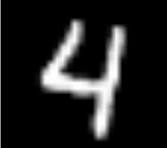

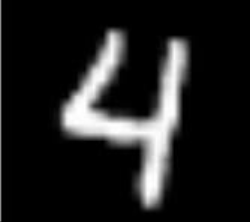

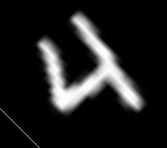

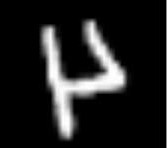

In [2]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
ImJPG = cv2.imread('/content/image.jpg')
m,n,_=ImJPG.shape
cv2_imshow(ImJPG)
scale_x = 1.5
scale_y = 1.5
affine_stretch = np.float32([
    [scale_x, 0, 0],
    [0, scale_y, 0]
])
stretched = cv2.warpAffine(ImJPG, affine_stretch, (int(n*scale_x), int(m*scale_y)))
cv2_imshow(stretched)
# 2. Rotation
angle = 45
center = (n//2, m//2)
rotation_affine = cv2.getRotationMatrix2D(center, angle, 1)
rotated = cv2.warpAffine(ImJPG, rotation_affine, (n, m))
cv2_imshow(rotated)
# 3. Reflection
reflected = cv2.flip(ImJPG, 1)
cv2_imshow(reflected)

